# Visualisasi Evaluasi HNSW

Notebook ini memakai CSV yang berada langsung di folder `evaluation/hnsw_eval_results` saja, tanpa membaca subfolder `m*_ef*`.

Rekomendasi utama untuk laporan tesis:

1. **Grafik utama:** Pareto scatter `latency_avg_ms` vs `mean_ndcg`, karena evaluasi HNSW sebenarnya adalah trade-off antara kecepatan dan kualitas hasil.
2. **Grafik pendamping:** heatmap parameter untuk melihat pola `m`, `ef_construct`, dan `hnsw_ef`.
3. **Grafik sesuai saran dosen:** stock-like/error range dengan sumbu x `m` dan sumbu y latensi. Grafik ini tetap dibuat, tetapi sebaiknya tidak menjadi satu-satunya grafik karena `m` saja tidak menjelaskan variasi performa.

In [2]:
from pathlib import Path
import os

# Matplotlib butuh folder konfigurasi yang writable di beberapa environment Linux.
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.titlesize": 12,
    "legend.fontsize": 8,
})

FINAL_GRID = "final_result_grid_ndcg_at_30.csv"

# Supaya notebook bisa dijalankan dari root repo maupun dari folder notebook.
candidate_dirs = [Path("."), Path("evaluation/hnsw_eval_results")]
DATA_DIR = next((p for p in candidate_dirs if (p / FINAL_GRID).exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(f"Tidak menemukan {FINAL_GRID}. Jalankan notebook dari root repo atau folder hnsw_eval_results.")

csv_files = sorted(DATA_DIR.glob("*.csv"))  # non-recursive, hanya CSV di folder ini
raw = {path.name: pd.read_csv(path) for path in csv_files}

grid = raw[FINAL_GRID].copy()
best_overall = raw.get("final_result_best_overall_ndcg_at_30.csv")
best_per_collection = raw.get("final_result_best_per_collection_ndcg_at_30.csv")

numeric_cols = [
    "overall_rank", "m", "ef_construct", "hnsw_ef", "qdrant_limit",
    "mean_ndcg", "min_ndcg", "max_ndcg", "mean_eval_search_ms",
    "mean_raw_hits", "mean_unique_hits", "mean_predicted_rows", "mean_used_rows",
    "latency_avg_ms", "latency_min_ms", "latency_max_ms", "latency_std_ms",
]
for df in [grid, best_overall, best_per_collection]:
    if df is None:
        continue
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

grid = grid.sort_values("overall_rank").reset_index(drop=True)
grid["config_label"] = (
    "m=" + grid["m"].astype(int).astype(str)
    + ", efc=" + grid["ef_construct"].astype(int).astype(str)
    + ", hnsw_ef=" + grid["hnsw_ef"].astype(int).astype(str)
    + ", limit=" + grid["qdrant_limit"].astype(int).astype(str)
)

print(f"Folder data: {DATA_DIR.resolve()}")
print("CSV top-level yang dibaca:")
for path in csv_files:
    print(f"- {path.name}: {len(raw[path.name]):,} rows")

Folder data: /home/vinik/Github/vector-search-thesis/evaluation/hnsw_eval_results
CSV top-level yang dibaca:
- all_collections_hnsw_detail_ndcg_at_30.csv: 20,324 rows
- all_collections_hnsw_latency.csv: 1,800 rows
- all_collections_hnsw_summary_ndcg_at_30.csv: 1,800 rows
- baseline_rank_qdrant_ndcg_at_30.csv: 4 rows
- final_result_best_overall_ndcg_at_30.csv: 20 rows
- final_result_best_per_collection_ndcg_at_30.csv: 9 rows
- final_result_grid_ndcg_at_30.csv: 450 rows


## Ringkasan Data

Cell ini memastikan kombinasi parameter yang tersedia di final result. Ini penting karena grafik `m` vs latensi perlu dibaca bersama parameter lain seperti `hnsw_ef`, `ef_construct`, dan `qdrant_limit`.

In [3]:
summary = pd.DataFrame({
    "jumlah_baris": [len(grid)],
    "m": [sorted(grid["m"].dropna().astype(int).unique().tolist())],
    "ef_construct": [sorted(grid["ef_construct"].dropna().astype(int).unique().tolist())],
    "hnsw_ef": [sorted(grid["hnsw_ef"].dropna().astype(int).unique().tolist())],
    "qdrant_limit": [sorted(grid["qdrant_limit"].dropna().astype(int).unique().tolist())],
    "mean_ndcg_min_max": [(grid["mean_ndcg"].min(), grid["mean_ndcg"].max())],
    "latency_avg_min_max_ms": [(grid["latency_avg_ms"].min(), grid["latency_avg_ms"].max())],
})
summary

,jumlah_baris,m,ef_construct,hnsw_ef,qdrant_limit,mean_ndcg_min_max,latency_avg_min_max_ms
0,450,"[8, 16, 32]","[100, 200, 400]","[16, 32, 64, 128, 256]","[10, 20, 30, 40, 50, 60, 70, 80, 90, 100]","(0.3630248920397889, 0.759278150336564)","(5.156227619954734, 11.290814269523253)"


In [4]:
grid.head(10)[[
    "overall_rank", "collection_id", "m", "ef_construct", "hnsw_ef", "qdrant_limit",
    "mean_ndcg", "latency_avg_ms", "latency_min_ms", "latency_max_ms", "latency_std_ms"
]]

,overall_rank,collection_id,m,ef_construct,hnsw_ef,qdrant_limit,mean_ndcg,latency_avg_ms,latency_min_ms,latency_max_ms,latency_std_ms
0,1,m8_ef400,8,400,256,100,0.759278,9.508657,6.092190,17.963043,2.536206
1,2,m16_ef200,16,200,128,100,0.754368,7.843068,5.580487,23.748651,1.992348
2,3,m16_ef400,16,400,64,100,0.752622,6.662223,5.155020,13.566785,1.378197
3,4,m16_ef400,16,400,128,100,0.751237,8.167479,5.845411,15.519503,1.711919
4,5,m8_ef400,8,400,128,100,0.751129,7.619170,5.376009,12.481183,1.461790
5,6,m32_ef100,32,100,256,100,0.750912,9.112087,6.042045,18.678792,1.946830
6,7,m16_ef200,16,200,64,100,0.749935,7.411691,4.936765,37.815896,2.576155
7,8,m32_ef200,32,200,256,100,0.748789,8.884558,6.006297,19.156611,1.870925
8,9,m16_ef400,16,400,256,100,0.745883,9.900054,6.610534,17.611546,2.558752
9,10,m32_ef400,32,400,64,100,0.745109,7.119891,5.128961,15.424303,1.714438


## Versi 1 - Stock-like / Error Range: `m` vs Latensi

Ini versi yang paling dekat dengan saran dosen pembimbing: sumbu x adalah `m`, sumbu y adalah latensi.

Interpretasi:

- Garis tipis menunjukkan rentang minimum sampai maksimum `latency_avg_ms` dari semua konfigurasi dengan `m` tersebut.
- Batang tebal menunjukkan Q1 sampai Q3, mirip badan candle.
- Titik menunjukkan rata-rata latensi.

Kelemahannya: grafik ini menyatukan banyak kombinasi `ef_construct`, `hnsw_ef`, dan `qdrant_limit`, jadi bagus sebagai ringkasan, bukan sebagai bukti utama performa HNSW.

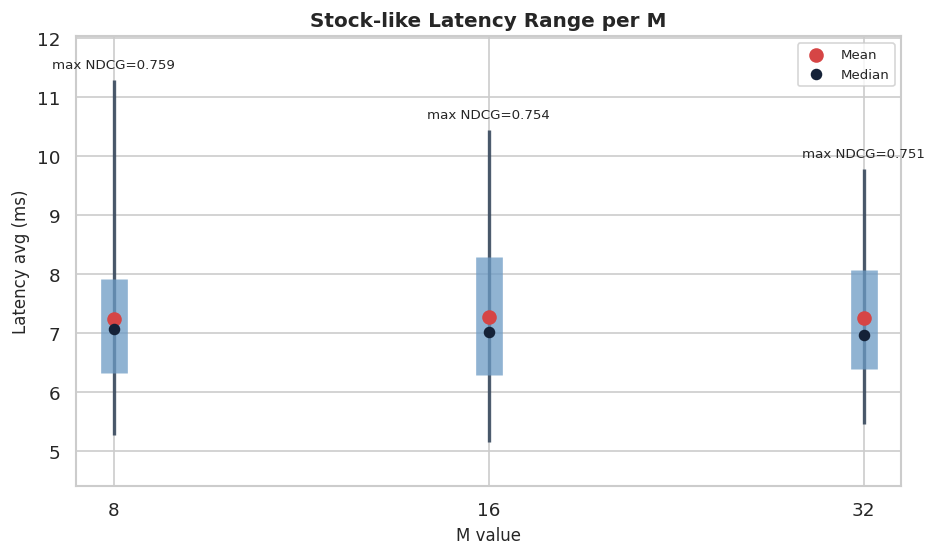

,m,latency_min,latency_q1,latency_mean,latency_median,latency_q3,latency_max,ndcg_mean,ndcg_max,rows
0,8,5.283352,6.323917,7.246779,7.064963,7.918007,11.290814,0.587147,0.759278,150
1,16,5.156228,6.284799,7.277146,7.013020,8.285558,10.438070,0.586401,0.754368,150
2,32,5.459700,6.390349,7.250624,6.975083,8.067694,9.784417,0.586608,0.750912,150


In [5]:
stock = (
    grid.groupby("m", as_index=False)
    .agg(
        latency_min=("latency_avg_ms", "min"),
        latency_q1=("latency_avg_ms", lambda s: s.quantile(0.25)),
        latency_mean=("latency_avg_ms", "mean"),
        latency_median=("latency_avg_ms", "median"),
        latency_q3=("latency_avg_ms", lambda s: s.quantile(0.75)),
        latency_max=("latency_avg_ms", "max"),
        ndcg_mean=("mean_ndcg", "mean"),
        ndcg_max=("mean_ndcg", "max"),
        rows=("latency_avg_ms", "size"),
    )
    .sort_values("m")
)

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(stock))

for i, row in stock.iterrows():
    ax.vlines(x[i], row["latency_min"], row["latency_max"], color="#2f4156", linewidth=2, alpha=0.85)
    ax.vlines(x[i], row["latency_q1"], row["latency_q3"], color="#6b9ac4", linewidth=16, alpha=0.75)
    ax.scatter(x[i], row["latency_mean"], color="#d64545", s=60, zorder=3, label="Mean" if i == 0 else None)
    ax.scatter(x[i], row["latency_median"], color="#152238", s=35, zorder=4, label="Median" if i == 0 else None)
    ax.text(x[i], row["latency_max"] + 0.15, f"max NDCG={row['ndcg_max']:.3f}", ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(stock["m"].astype(int))
ax.set_xlabel("M value")
ax.set_ylabel("Latency avg (ms)")
ax.set_title("Stock-like Latency Range per M")
ax.legend(frameon=True, loc="upper right")
ax.margins(y=0.12)
plt.tight_layout()
plt.show()

stock

## Versi 2 - Boxplot Distribusi Latensi per `m`

Jika tetap ingin sumbu x `m` dan sumbu y latensi, boxplot lebih jujur daripada stock-like karena memperlihatkan distribusi semua konfigurasi. Titik-titik diwarnai berdasarkan `ef_construct` agar terlihat bahwa variasi latensi bukan hanya akibat `m`.

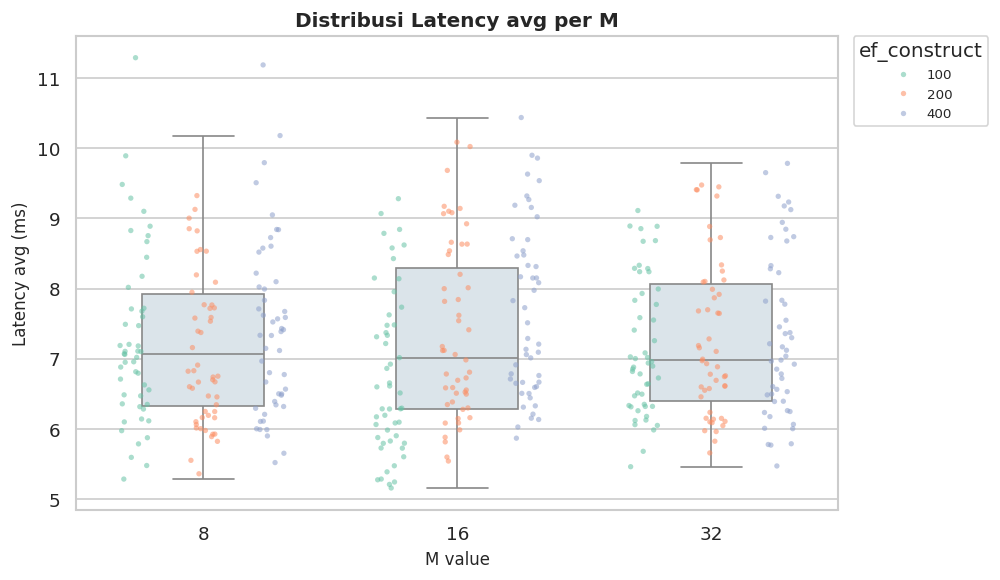

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.boxplot(
    data=grid,
    x="m",
    y="latency_avg_ms",
    color="#d9e4ec",
    width=0.48,
    showfliers=False,
    ax=ax,
)
sns.stripplot(
    data=grid,
    x="m",
    y="latency_avg_ms",
    hue="ef_construct",
    palette="Set2",
    dodge=True,
    jitter=0.18,
    size=3.2,
    alpha=0.55,
    ax=ax,
)
ax.set_xlabel("M value")
ax.set_ylabel("Latency avg (ms)")
ax.set_title("Distribusi Latency avg per M")
ax.legend(title="ef_construct", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

## Versi 3 - Rekomendasi Utama: Pareto Scatter NDCG vs Latensi

Grafik ini lebih kuat untuk tesis karena HNSW tidak hanya mengejar latensi rendah. Konfigurasi yang baik adalah yang berada di kiri-atas: latensi rendah dan `mean_ndcg` tinggi.

Garis Pareto menunjukkan konfigurasi yang tidak didominasi konfigurasi lain. Artinya, untuk menaikkan NDCG dari titik tersebut, biasanya harus menerima latensi yang lebih tinggi.

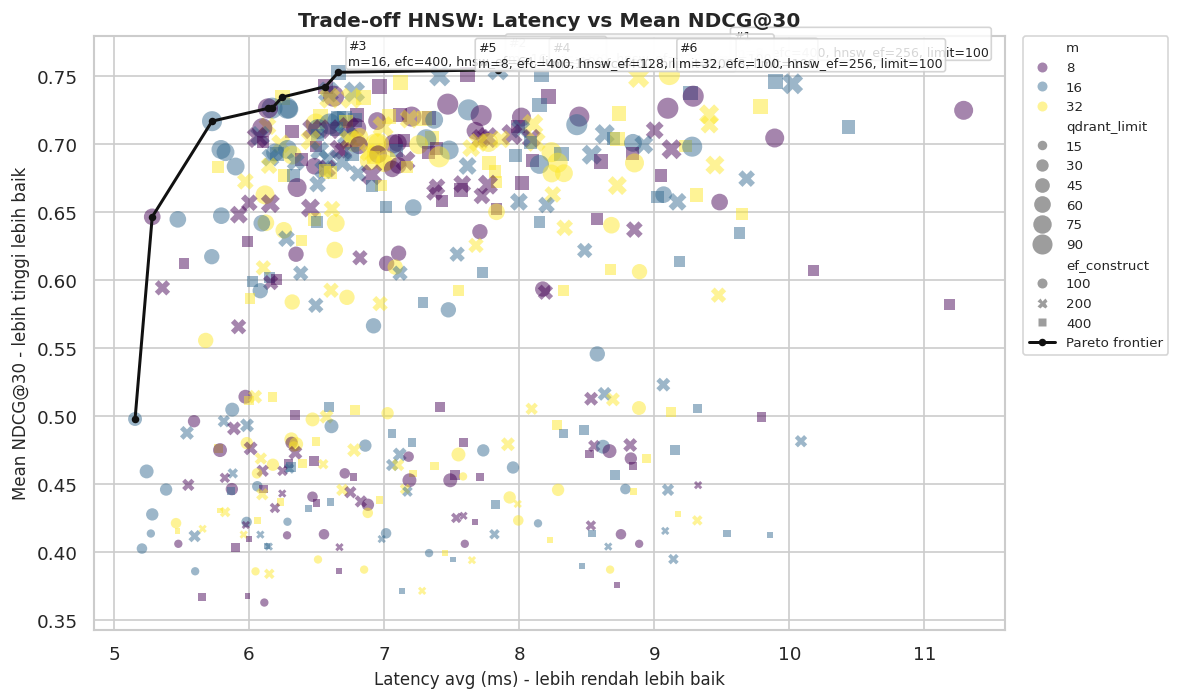

,overall_rank,collection_id,m,ef_construct,hnsw_ef,qdrant_limit,mean_ndcg,latency_avg_ms
290,291,m16_ef100,16,100,16,40,0.497848,5.156228
209,210,m8_ef100,8,100,16,60,0.646379,5.283352
51,52,m16_ef100,16,100,32,90,0.716665,5.726036
29,30,m8_ef100,8,100,64,90,0.726072,6.139882
26,27,m16_ef100,16,100,16,100,0.726210,6.170706
19,20,m32_ef400,32,400,16,100,0.734363,6.246418
11,12,m8_ef400,8,400,16,100,0.742050,6.565875
2,3,m16_ef400,16,400,64,100,0.752622,6.662223
1,2,m16_ef200,16,200,128,100,0.754368,7.843068
0,1,m8_ef400,8,400,256,100,0.759278,9.508657


In [7]:
def pareto_frontier(df, x_col="latency_avg_ms", y_col="mean_ndcg"):
    ordered = df.sort_values([x_col, y_col], ascending=[True, False]).copy()
    best_y = -np.inf
    selected_idx = []
    for idx, row in ordered.iterrows():
        if row[y_col] > best_y + 1e-12:
            selected_idx.append(idx)
            best_y = row[y_col]
    return df.loc[selected_idx].sort_values(x_col)

pareto = pareto_frontier(grid)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=grid,
    x="latency_avg_ms",
    y="mean_ndcg",
    hue="m",
    style="ef_construct",
    size="qdrant_limit",
    sizes=(25, 160),
    palette="viridis",
    alpha=0.48,
    edgecolor="none",
    ax=ax,
)
ax.plot(pareto["latency_avg_ms"], pareto["mean_ndcg"], color="#111111", linewidth=1.8, marker="o", markersize=3.5, label="Pareto frontier")

label_df = grid.nsmallest(6, "overall_rank")
for _, row in label_df.iterrows():
    ax.annotate(
        f"#{int(row['overall_rank'])}\n{row['config_label']}",
        xy=(row["latency_avg_ms"], row["mean_ndcg"]),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=7.5,
        color="#222222",
        bbox={"boxstyle": "round,pad=0.2", "fc": "white", "ec": "#cccccc", "alpha": 0.82},
    )

ax.set_xlabel("Latency avg (ms) - lebih rendah lebih baik")
ax.set_ylabel("Mean NDCG@30 - lebih tinggi lebih baik")
ax.set_title("Trade-off HNSW: Latency vs Mean NDCG@30")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, frameon=True)
plt.tight_layout()
plt.show()

pareto[["overall_rank", "collection_id", "m", "ef_construct", "hnsw_ef", "qdrant_limit", "mean_ndcg", "latency_avg_ms"]]

## Versi 4 - Heatmap Parameter

Heatmap cocok untuk melihat pola pengaruh parameter. Cell ini memakai `qdrant_limit` terbesar secara default karena konfigurasi terbaik di final result cenderung berada pada limit tinggi. Ubah `SELECT_QDRANT_LIMIT` jika ingin membandingkan limit lain.

- Heatmap NDCG: makin gelap berarti kualitas hasil makin baik.
- Heatmap latensi: makin gelap berarti latensi makin tinggi.

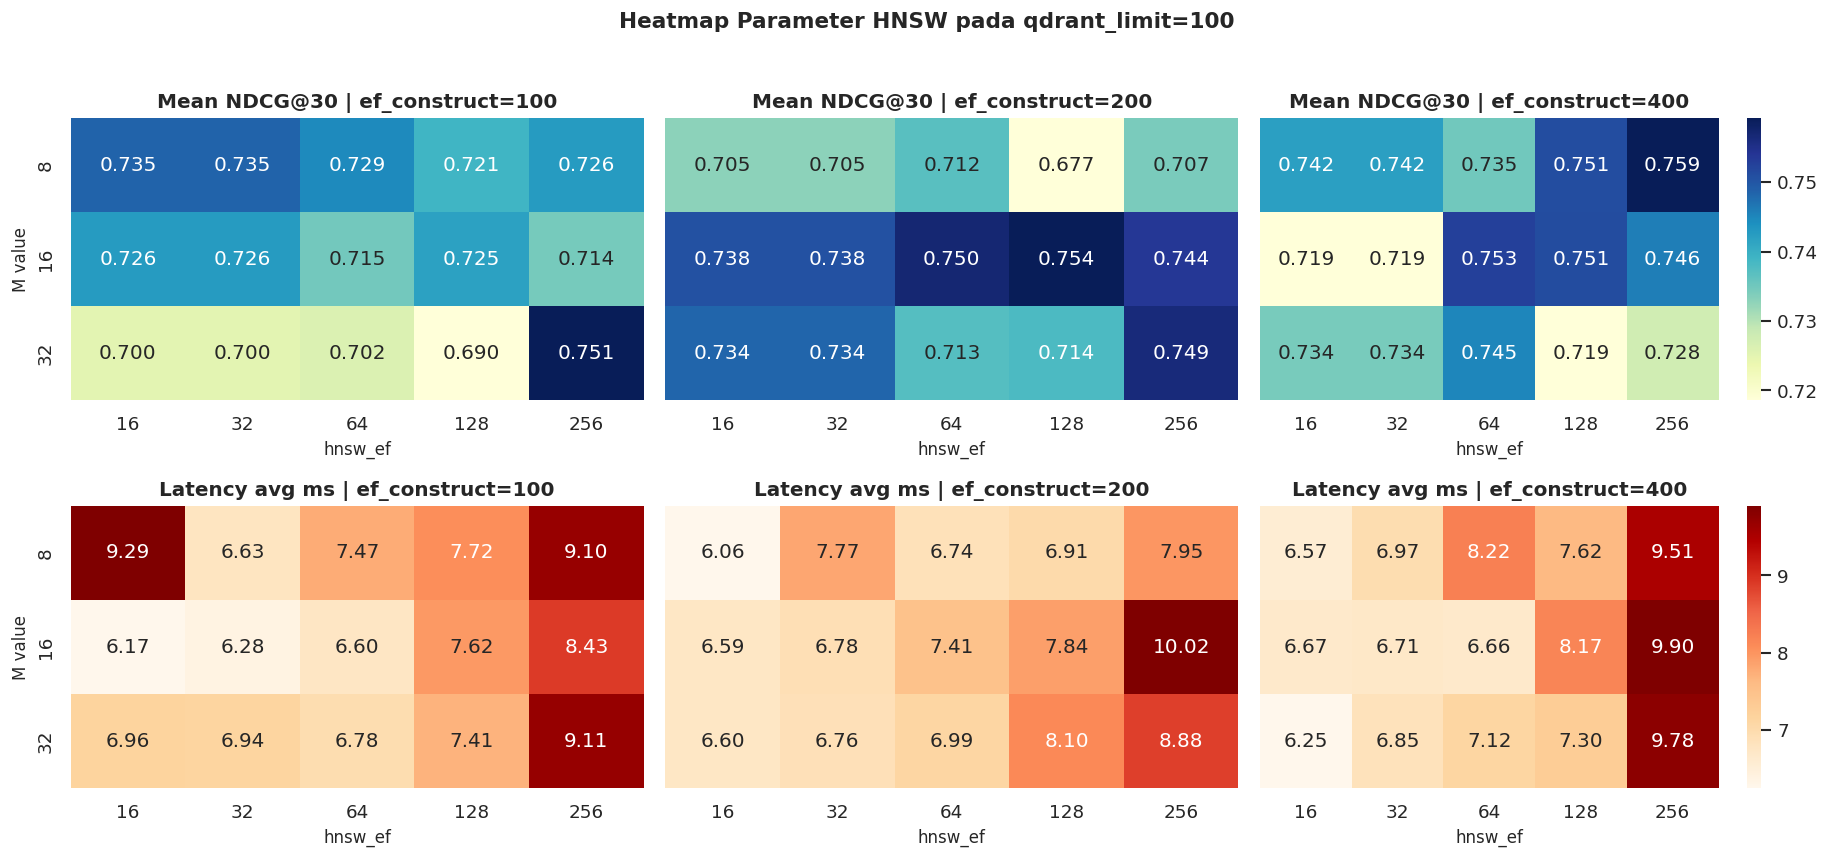

In [8]:
SELECT_QDRANT_LIMIT = int(grid["qdrant_limit"].max())
heat_df = grid[grid["qdrant_limit"] == SELECT_QDRANT_LIMIT].copy()

agg_heat = (
    heat_df.groupby(["ef_construct", "m", "hnsw_ef"], as_index=False)
    .agg(mean_ndcg=("mean_ndcg", "mean"), latency_avg_ms=("latency_avg_ms", "mean"))
)

ef_values = sorted(agg_heat["ef_construct"].dropna().astype(int).unique())

fig, axes = plt.subplots(2, len(ef_values), figsize=(5.2 * len(ef_values), 7), sharex=False, sharey=True)
if len(ef_values) == 1:
    axes = np.array([[axes[0]], [axes[1]]])

for col_idx, efc in enumerate(ef_values):
    subset = agg_heat[agg_heat["ef_construct"] == efc]
    ndcg_pivot = subset.pivot(index="m", columns="hnsw_ef", values="mean_ndcg").sort_index().sort_index(axis=1)
    lat_pivot = subset.pivot(index="m", columns="hnsw_ef", values="latency_avg_ms").sort_index().sort_index(axis=1)

    sns.heatmap(ndcg_pivot, annot=True, fmt=".3f", cmap="YlGnBu", cbar=col_idx == len(ef_values) - 1, ax=axes[0, col_idx])
    axes[0, col_idx].set_title(f"Mean NDCG@30 | ef_construct={efc}")
    axes[0, col_idx].set_xlabel("hnsw_ef")
    axes[0, col_idx].set_ylabel("M value" if col_idx == 0 else "")

    sns.heatmap(lat_pivot, annot=True, fmt=".2f", cmap="OrRd", cbar=col_idx == len(ef_values) - 1, ax=axes[1, col_idx])
    axes[1, col_idx].set_title(f"Latency avg ms | ef_construct={efc}")
    axes[1, col_idx].set_xlabel("hnsw_ef")
    axes[1, col_idx].set_ylabel("M value" if col_idx == 0 else "")

fig.suptitle(f"Heatmap Parameter HNSW pada qdrant_limit={SELECT_QDRANT_LIMIT}", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## Versi 5 - Line Chart `m` vs Latensi, Dipisah `ef_construct`

Ini masih mengikuti ide sumbu x `m`, tetapi lebih informatif karena garisnya dipisah berdasarkan `hnsw_ef` dan panelnya dipisah berdasarkan `ef_construct`. Filter default memakai `qdrant_limit` terbesar agar sebanding dengan heatmap.

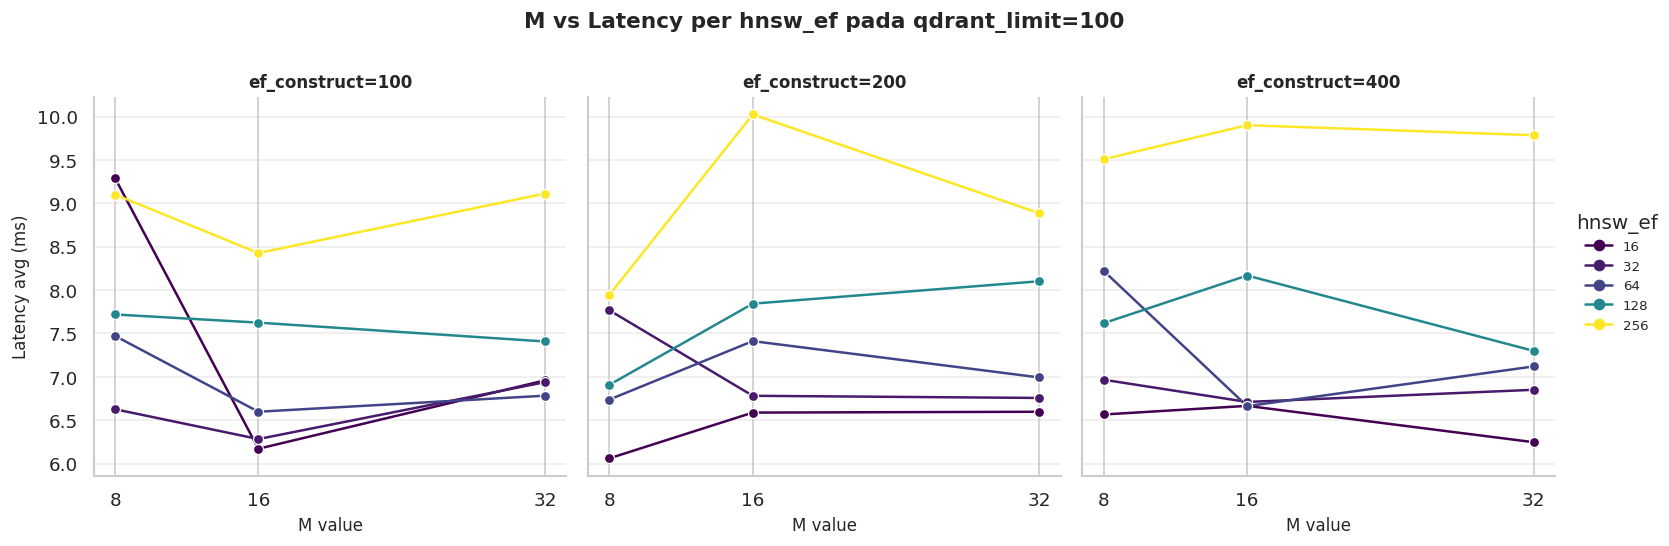

,ef_construct,m,hnsw_ef,latency_avg_ms,mean_ndcg
15,200,8,16,6.060816,0.704610
5,100,16,16,6.170706,0.726210
40,400,32,16,6.246418,0.734363
6,100,16,32,6.282662,0.726210
30,400,8,16,6.565875,0.742050
20,200,16,16,6.587715,0.738069
25,200,32,16,6.597299,0.733622
7,100,16,64,6.597580,0.714583
1,100,8,32,6.626198,0.735005
37,400,16,64,6.662223,0.752622


In [9]:
line_df = (
    grid[grid["qdrant_limit"] == SELECT_QDRANT_LIMIT]
    .groupby(["ef_construct", "m", "hnsw_ef"], as_index=False)
    .agg(latency_avg_ms=("latency_avg_ms", "mean"), mean_ndcg=("mean_ndcg", "mean"))
)

g = sns.relplot(
    data=line_df,
    x="m",
    y="latency_avg_ms",
    hue="hnsw_ef",
    col="ef_construct",
    kind="line",
    marker="o",
    palette="viridis",
    height=4.2,
    aspect=1.05,
    facet_kws={"sharey": True},
)
g.set_axis_labels("M value", "Latency avg (ms)")
g.set_titles("ef_construct={col_name}")
for ax in g.axes.flat:
    ax.set_xticks(sorted(line_df["m"].unique()))
    ax.grid(True, axis="y", alpha=0.35)
g.fig.suptitle(f"M vs Latency per hnsw_ef pada qdrant_limit={SELECT_QDRANT_LIMIT}", y=1.08, fontsize=13, fontweight="bold")
plt.show()

line_df.sort_values(["latency_avg_ms", "mean_ndcg"], ascending=[True, False]).head(10)

## Versi 6 - Top Konfigurasi Final Result

Grafik ini cocok untuk bagian hasil akhir karena langsung menunjukkan konfigurasi terbaik berdasarkan ranking `final_result_grid_ndcg_at_30.csv`. Label di kanan bar menunjukkan latensi rata-rata, sehingga pembaca bisa melihat apakah kenaikan NDCG dibayar dengan latensi yang lebih besar.

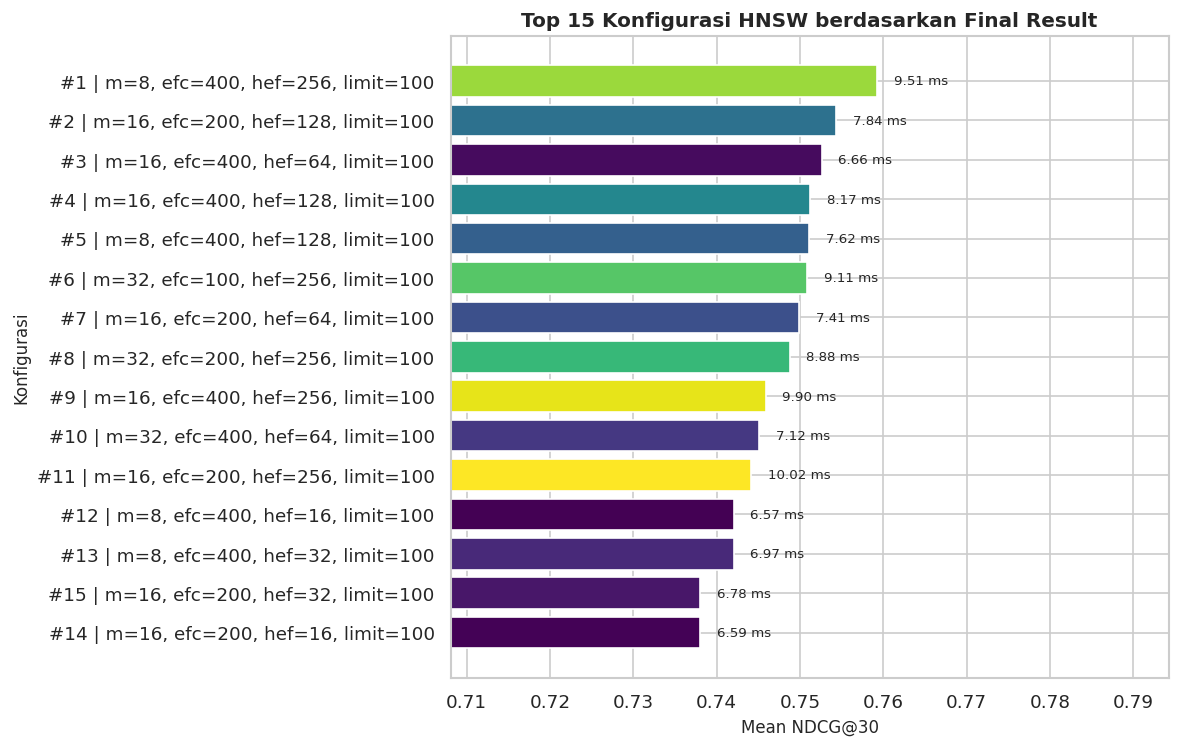

,overall_rank,collection_id,m,ef_construct,hnsw_ef,qdrant_limit,mean_ndcg,min_ndcg,max_ndcg,latency_avg_ms,latency_min_ms,latency_max_ms,latency_std_ms
0,1,m8_ef400,8,400,256,100,0.759278,0.702977,0.83672,9.508657,6.092190,17.963043,2.536206
1,2,m16_ef200,16,200,128,100,0.754368,0.657336,0.83672,7.843068,5.580487,23.748651,1.992348
2,3,m16_ef400,16,400,64,100,0.752622,0.676352,0.83672,6.662223,5.155020,13.566785,1.378197
3,4,m16_ef400,16,400,128,100,0.751237,0.644809,0.83672,8.167479,5.845411,15.519503,1.711919
4,5,m8_ef400,8,400,128,100,0.751129,0.670381,0.83672,7.619170,5.376009,12.481183,1.461790
5,6,m32_ef100,32,100,256,100,0.750912,0.669514,0.83672,9.112087,6.042045,18.678792,1.946830
6,7,m16_ef200,16,200,64,100,0.749935,0.691368,0.83672,7.411691,4.936765,37.815896,2.576155
7,8,m32_ef200,32,200,256,100,0.748789,0.661020,0.83672,8.884558,6.006297,19.156611,1.870925
8,9,m16_ef400,16,400,256,100,0.745883,0.676352,0.83672,9.900054,6.610534,17.611546,2.558752
9,10,m32_ef400,32,400,64,100,0.745109,0.646302,0.83672,7.119891,5.128961,15.424303,1.714438


In [10]:
TOP_N = 15
top = grid.nsmallest(TOP_N, "overall_rank").copy()
top["short_label"] = (
    "#" + top["overall_rank"].astype(int).astype(str)
    + " | m=" + top["m"].astype(int).astype(str)
    + ", efc=" + top["ef_construct"].astype(int).astype(str)
    + ", hef=" + top["hnsw_ef"].astype(int).astype(str)
    + ", limit=" + top["qdrant_limit"].astype(int).astype(str)
)
top = top.sort_values("mean_ndcg", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6.4))
bars = ax.barh(top["short_label"], top["mean_ndcg"], color=plt.cm.viridis((top["latency_avg_ms"] - top["latency_avg_ms"].min()) / (top["latency_avg_ms"].max() - top["latency_avg_ms"].min() + 1e-9)))

for bar, (_, row) in zip(bars, top.iterrows()):
    ax.text(
        row["mean_ndcg"] + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{row['latency_avg_ms']:.2f} ms",
        va="center",
        fontsize=8,
    )

ax.set_xlabel("Mean NDCG@30")
ax.set_ylabel("Konfigurasi")
ax.set_title(f"Top {TOP_N} Konfigurasi HNSW berdasarkan Final Result")
ax.set_xlim(max(0, top["mean_ndcg"].min() - 0.03), min(1, top["mean_ndcg"].max() + 0.035))
plt.tight_layout()
plt.show()

grid.nsmallest(TOP_N, "overall_rank")[[
    "overall_rank", "collection_id", "m", "ef_construct", "hnsw_ef", "qdrant_limit",
    "mean_ndcg", "min_ndcg", "max_ndcg", "latency_avg_ms", "latency_min_ms", "latency_max_ms", "latency_std_ms"
]]

## Catatan untuk Penulisan Bab Hasil

Menurut saya, grafik yang paling baik untuk ditampilkan adalah **Pareto scatter latency vs mean NDCG@30** sebagai grafik utama. Alasannya, konfigurasi HNSW tidak bisa dinilai dari latensi saja. Parameter yang lebih cepat belum tentu menghasilkan ranking yang baik, sementara konfigurasi dengan NDCG terbaik bisa saja menambah latensi.

Grafik stock-like `m` vs latensi tetap layak dimasukkan sebagai grafik pendamping untuk memenuhi saran dosen. Namun, penjelasannya perlu hati-hati: dari final result ini, variasi rata-rata latensi antar `m` terlihat kecil, sehingga faktor seperti `hnsw_ef`, `ef_construct`, dan `qdrant_limit` perlu ikut dianalisis.

Susunan grafik yang saya sarankan di laporan:

1. Pareto scatter `latency_avg_ms` vs `mean_ndcg` untuk memilih konfigurasi terbaik.
2. Heatmap parameter untuk menjelaskan pola kombinasi `m`, `ef_construct`, dan `hnsw_ef`.
3. Stock-like atau boxplot `m` vs latensi sebagai ringkasan khusus sesuai arahan pembimbing.
4. Bar chart top konfigurasi untuk menutup bagian hasil dengan konfigurasi final yang direkomendasikan.